# LassoSelector: speed and reproducibility

This notebook times LassoSelector's two solvers and checks that every fit
gives the same genes. It ends with a verdict per dataset: which solver is
faster, and by how much.

**Variants.**

- **scikit-learn**: LogisticRegression(l1_ratio=1, solver='liblinear',
  C=1), its default tolerance 1e-4. This is LassoSelector's default solver.
- **featsel PPDNA, GPU**: solver='ppdna', device='cuda'. The same L1
  logistic regression solved to a tight tolerance on the GPU (see
  `ppdna.py`). On the CPU it is about five times slower than liblinear, so
  it is not timed here.

**Agreement.** PPDNA matches liblinear run to a tight tolerance (the tests
check this). liblinear's default tolerance stops early and keeps slightly
different genes, so `jaccard_vs_original` is near 1 but not 1.

**Data.**

1. Synthetic, shaped like SCAN-B: 3,000 patients, one in five positive, 50
   informative genes among 30,000. Each variant fits on the first 1,000,
   3,000, 10,000 and 30,000 genes.
2. SCAN-B (GSE96058): all 2,976 patients and all genes, standardized as the
   experiments do. The five PAM50 tasks, each subtype against the rest, are
   five binary datasets.

**Each row of a table.** One variant on one dataset:

- `median_s`, `min_s`, `max_s`: seconds per fit, over 2 timed fits after
  one untimed fit (CUDA starts then).
- `reproducible`: every fit, the untimed one included, chose the same genes.
- `jaccard_vs_original`: overlap of its genes with liblinear's.

Times hold for this machine only. The JSON written beside each CSV records it.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

import featsel
from featsel import benchmark, environment
from featsel.run import build_tasks

NAME = 'LassoSelector'
OUT = Path(featsel.__file__).parents[1] / 'results' / 'local' / 'speed'
OUT.mkdir(parents=True, exist_ok=True)


def verdict(table, key):
    """Per dataset: each variant's time and speed against liblinear's."""
    for name, part in table.groupby(key, sort=False):
        original = part.iloc[0]
        for _, row in part.iloc[1:].iterrows():
            ratio = original['median_s'] / row['median_s']
            faster = f"{ratio:.1f}x faster" if ratio >= 1 else f"{1 / ratio:.1f}x slower"
            print(f"{name!s:>12}: {row['variant']} {row['median_s']:.2f} s, "
                  f"liblinear {original['median_s']:.2f} s -> {faster}; "
                  f"reproducible {bool(part['reproducible'].all())}, "
                  f"Jaccard {row['jaccard_vs_original']:.3f}")


print(f"Memory cap: {benchmark.cap_memory():.1f} GB")
print("Variants:", ', '.join(benchmark.variants(NAME)))

Memory cap: 7.6 GB


Variants: scikit-learn, featsel PPDNA, GPU


## 1. Synthetic data, growing gene counts

In [2]:
X, y = benchmark.synthetic()
print(f"{X.shape[0]} patients x {X.shape[1]} genes, {y.sum()} positive")
table = benchmark.benchmark(NAME, X, y)
table.to_csv(OUT / f'{NAME}.csv', index=False)
environment.write_json((OUT / f'{NAME}.csv').with_suffix('.json'), selector=NAME,
                       params=benchmark.PARAMS[NAME], n_patients=int(X.shape[0]))
table.round(4)

3000 patients x 30000 genes, 603 positive


,variant,device,n_genes,n_patients,fits,median_s,min_s,max_s,n_selected,reproducible,jaccard_vs_original
0,scikit-learn,cpu,1000,3000,3,0.7863,0.7844,0.7881,948,True,1.0000
1,scikit-learn,cpu,3000,3000,3,2.0343,2.0310,2.0377,1466,True,1.0000
2,scikit-learn,cpu,10000,3000,3,2.8812,2.7923,2.9701,1662,True,1.0000
3,scikit-learn,cpu,30000,3000,3,5.6580,5.6261,5.6899,1330,True,1.0000
4,"featsel PPDNA, GPU",cuda,1000,3000,3,0.4127,0.4121,0.4133,948,True,1.0000
5,"featsel PPDNA, GPU",cuda,3000,3000,3,0.6524,0.6459,0.6590,1466,True,0.9973
6,"featsel PPDNA, GPU",cuda,10000,3000,3,0.9568,0.9420,0.9716,1662,True,0.9809
7,"featsel PPDNA, GPU",cuda,30000,3000,3,1.0780,1.0756,1.0805,1322,True,0.9093


In [3]:
verdict(table, 'n_genes')

        1000: featsel PPDNA, GPU 0.41 s, liblinear 0.79 s -> 1.9x faster; reproducible True, Jaccard 1.000
        3000: featsel PPDNA, GPU 0.65 s, liblinear 2.03 s -> 3.1x faster; reproducible True, Jaccard 0.997
       10000: featsel PPDNA, GPU 0.96 s, liblinear 2.88 s -> 3.0x faster; reproducible True, Jaccard 0.981
       30000: featsel PPDNA, GPU 1.08 s, liblinear 5.66 s -> 5.2x faster; reproducible True, Jaccard 0.909


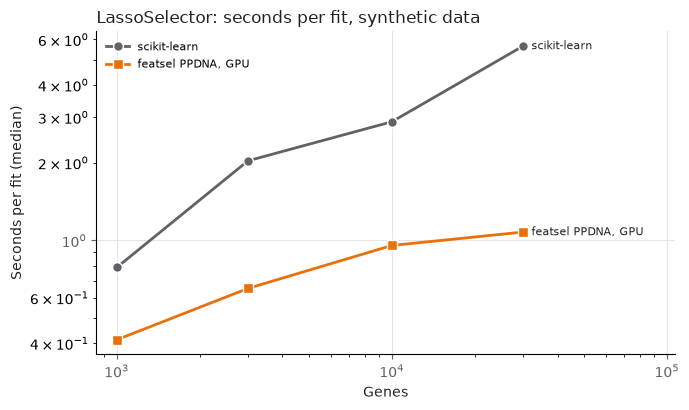

In [4]:
fig = benchmark.plot(table, f"{NAME}: seconds per fit, synthetic data")

## 2. SCAN-B, the five PAM50 tasks

Loading GSE96058 takes about a minute; the first run downloads it (592 MB).

In [5]:
from featsel_datasets.scanb_gse96058.featsel_view import load_xy

X_df, y_df = load_xy()
X = StandardScaler().fit_transform(X_df.to_numpy(dtype=np.float32)).astype(np.float32)
print(f"{X.shape[0]} patients x {X.shape[1]} genes")

rows = []
for task, y_task in build_tasks(y_df.to_numpy()):
    positive = y_task != 'rest'
    part = benchmark.benchmark(NAME, X, positive.astype(int), n_genes=(X.shape[1],))
    part.insert(0, 'task', task)
    part.insert(1, 'n_positive', int(positive.sum()))
    rows.append(part)
scanb = pd.concat(rows, ignore_index=True)
scanb.to_csv(OUT / f'{NAME}_scanb.csv', index=False)
environment.write_json((OUT / f'{NAME}_scanb.csv').with_suffix('.json'), selector=NAME,
                       params=benchmark.PARAMS[NAME], n_patients=int(X.shape[0]),
                       dataset='SCAN-B GSE96058, PAM50 one-vs-rest, standardized')
scanb.round(4)

2976 patients x 28552 genes


,task,n_positive,variant,device,n_genes,n_patients,fits,median_s,min_s,max_s,n_selected,reproducible,jaccard_vs_original
0,ovr_Basal,308,scikit-learn,cpu,28552,2976,3,4.9923,4.8100,5.1747,330,True,1.0000
1,ovr_Basal,308,"featsel PPDNA, GPU",cuda,28552,2976,3,0.7162,0.7160,0.7165,196,True,0.5516
2,ovr_Her2,297,scikit-learn,cpu,28552,2976,3,4.6513,4.6112,4.6913,571,True,1.0000
3,ovr_Her2,297,"featsel PPDNA, GPU",cuda,28552,2976,3,0.9200,0.9124,0.9276,430,True,0.6852
4,ovr_LumA,1502,scikit-learn,cpu,28552,2976,3,4.5138,4.3477,4.6800,1600,True,1.0000
5,ovr_LumA,1502,"featsel PPDNA, GPU",cuda,28552,2976,3,1.4102,1.4085,1.4118,907,True,0.5084
6,ovr_LumB,669,scikit-learn,cpu,28552,2976,3,4.7753,4.7015,4.8492,1029,True,1.0000
7,ovr_LumB,669,"featsel PPDNA, GPU",cuda,28552,2976,3,1.4011,1.3894,1.4127,733,True,0.5845
8,ovr_Normal,200,scikit-learn,cpu,28552,2976,3,5.7978,5.4533,6.1423,577,True,1.0000
9,ovr_Normal,200,"featsel PPDNA, GPU",cuda,28552,2976,3,0.8655,0.8449,0.8860,542,True,0.8807


In [6]:
verdict(scanb, 'task')

   ovr_Basal: featsel PPDNA, GPU 0.72 s, liblinear 4.99 s -> 7.0x faster; reproducible True, Jaccard 0.552
    ovr_Her2: featsel PPDNA, GPU 0.92 s, liblinear 4.65 s -> 5.1x faster; reproducible True, Jaccard 0.685
    ovr_LumA: featsel PPDNA, GPU 1.41 s, liblinear 4.51 s -> 3.2x faster; reproducible True, Jaccard 0.508
    ovr_LumB: featsel PPDNA, GPU 1.40 s, liblinear 4.78 s -> 3.4x faster; reproducible True, Jaccard 0.585
  ovr_Normal: featsel PPDNA, GPU 0.87 s, liblinear 5.80 s -> 6.7x faster; reproducible True, Jaccard 0.881
